# Практическое занятие №1. Линейная регрессия

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Датасет **Abalone** (морские ушки, репозиторий UCI). Каждая строка — одно
животное, у которого измерили размеры и вес, а последний столбец `Rings`
(число колец на раковине) — это его возраст в пересчёте на годы. Задача —
**предсказать число колец по остальным признакам**.

Что делаем и зачем:

1. **Данные** — скачиваем датасет, разбираемся, что в нём есть.
2. **Проверка и очистка** — дубликаты, пропуски, аномалии. Даже если датасет
   чистый, код проверки обязателен: он показывает, что мы действительно
   смотрели на данные, а не просто начитали с ними работу.
3. **Разведочный анализ** — распределения, связь пола с признаками,
   матрица корреляций.
4. **Подготовка** — One-Hot кодирование пола, масштабирование числовых
   признаков, разделение на train / validation / test.
5. **Модель** — линейная регрессия (метод наименьших квадратов).
6. **Обучение и оценка** — метрики на тесте и сравнение с базовой линией.

## Почему линейная регрессия

Число колец — физическая величина, зависящая от размера и веса животного,
поэтому зависимость ожидается монотонной и почти линейной: «больше ушка —
больше колец». Линейная регрессия — самая простая и самая интерпретируемая
модель: у каждого признака есть коэффициент, который можно прочитать и
осмыслить. Это честная отправная точка, с которой потом сравнивают всё
остальное.

Работа построена так, чтобы результат был **честным**: гиперпараметры и
выбор модели делаются по валидационной выборке, тестовая используется один
раз в самом конце.


In [1]:
# Ячейка 1 — зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, — иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла: так сразу видно,
# на чём построена работа, и ниже по ноутбуку нигде не появляется
# «внезапный» импорт.
from io import StringIO                     # текст датасета превращаем в таблицу без временного файла
from pathlib import Path                    # работа с файлами: локальная копия датасета
from statistics import NormalDist           # теоретические квантили нормального распределения для Q-Q графика
from urllib.request import urlopen          # загрузка датасета с сайта UCI, если локальной копии нет

import numpy as np                         # численные массивы
import pandas as pd                        # таблицы: чтение данных, кодирование, статистика
import matplotlib.pyplot as plt             # базовые графики
import seaborn as sns                       # читаемые графики и тепловая карта корреляций

from sklearn.model_selection import train_test_split        # разделение на train / validation / test
from sklearn.preprocessing import StandardScaler             # масштабирование числовых признаков
from sklearn.preprocessing import PolynomialFeatures        # нелинейные признаки для контрольного эксперимента
from sklearn.pipeline import Pipeline                        # «преобразования → модель», чтобы не допустить утечки
from sklearn.linear_model import LinearRegression, Ridge     # сама модель и её регуляризованный вариант
from sklearn.dummy import DummyRegressor                     # базовая линия: предсказание среднего
from sklearn.metrics import (                                # метрики качества регрессии
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)


In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел, иначе каждый запуск
# ноутбука давал бы немного разные результаты.
SEED = 42
np.random.seed(SEED)

# Графики должны попадать в вывод ноутбука как картинки — это делает inline-режим.
%matplotlib inline

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 140)


## 1. Данные

**Abalone (UCI)** — классический датасет для регрессии. 4177 морских ушек,
снятых у австралийского побережья; для каждого измерены семь числовых
признаков и пол особи, а число колец на раковине известно точно — оно и
является целевой переменной.

Схема данных: файл без заголовка, поля разделены запятыми (в части зеркал
репозитория — пробелами, поэтому ноутбук определяет разделитель сам),
целевая переменная в последнем столбце `Rings`.


In [4]:
# Датасет лежит рядом с ноутбуком; если файла нет (например, ноутбук открыли в
# Colab), берём его напрямую с сайта UCI. Оба пути ведут к одному и тому же файлу.
DATA_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
            "abalone/abalone.data")
DATA_PATH = Path("data/abalone.data")

COLUMNS = ["Sex", "Length", "Diameter", "Height",
           "Whole weight", "Shucked weight", "Viscera weight", "Shell weight",
           "Rings"]

def load_raw_text() -> str:
    """Отдаёт содержимое файла датасета: с диска, а при отсутствии — из сети."""
    if DATA_PATH.exists():
        return DATA_PATH.read_text(encoding="utf-8")
    with urlopen(DATA_URL, timeout=60) as response:
        return response.read().decode("utf-8")

raw_text = load_raw_text()
source = f"локальный файл {DATA_PATH}" if DATA_PATH.exists() else DATA_URL
print(f"источник данных: {source}")
print(f"объём: {len(raw_text):,} символов, строк: {len(raw_text.splitlines()):,}")


источник данных: локальный файл data\abalone.data
объём: 191,873 символов, строк: 4,177


In [5]:
# В файле нет заголовка, поэтому имена столбцов задаём сами. Разделитель в
# файле — запятая (в некоторых зеркалах репозитория — пробелы), поэтому берём
# регулярное выражение, которое аккуратно разбирает оба варианта.
first_line = raw_text.splitlines()[0]
separator = "," if "," in first_line else r"\s+"
print(f"разделитель в файле: {separator!r} (проверено по первой строке)")

data = pd.read_csv(StringIO(raw_text), sep=separator, names=COLUMNS)
print("размер таблицы:", data.shape)
data.head()


разделитель в файле: ',' (проверено по первой строке)
размер таблицы: (4177, 9)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [6]:
# Что означает каждый столбец и в каких единицах измерен: без этого
# коэффициенты модели невозможно прочитать осмысленно.
MEANING = pd.DataFrame({
    "признак": COLUMNS,
    "единица": ["—", "мм", "мм", "мм", "г", "г", "г", "г", "колец"],
    "смысл": ["пол особи: M — самец, F — самка, I — незрелая особь",
              "длина раковины", "поперечный диаметр", "высота раковины",
              "вес целого животного", "вес мягких тканей без раковины",
              "вес внутренних органов", "вес раковины",
              "число колец = возраст (целевая переменная)"],
}).set_index("признак")

MEANING


,единица,смысл
признак,,
Sex,—,"пол особи: M — самец, F — самка, I — незрелая особь"
Length,мм,длина раковины
Diameter,мм,поперечный диаметр
Height,мм,высота раковины
Whole weight,г,вес целого животного
Shucked weight,г,вес мягких тканей без раковины
Viscera weight,г,вес внутренних органов
Shell weight,г,вес раковины
Rings,колец,число колец = возраст (целевая переменная)


In [7]:
# Типы столбцов: если бы где-то вместо числа оказалась буква или пустое поле,
# pandas проставил бы здесь object — это первый сигнал «битых» данных.
print(data.dtypes)
print()
print(data.describe().round(3).T)


Sex                   str
Length            float64
Diameter          float64
Height            float64
Whole weight      float64
Shucked weight    float64
Viscera weight    float64
Shell weight      float64
Rings               int64
dtype: object



                 count   mean    std    min    25%    50%     75%     max
Length          4177.0  0.524  0.120  0.075  0.450  0.545   0.615   0.815
Diameter        4177.0  0.408  0.099  0.055  0.350  0.425   0.480   0.650
Height          4177.0  0.140  0.042  0.000  0.115  0.140   0.165   1.130
Whole weight    4177.0  0.829  0.490  0.002  0.442  0.800   1.153   2.826
Shucked weight  4177.0  0.359  0.222  0.001  0.186  0.336   0.502   1.488
Viscera weight  4177.0  0.181  0.110  0.000  0.094  0.171   0.253   0.760
Shell weight    4177.0  0.239  0.139  0.002  0.130  0.234   0.329   1.005
Rings           4177.0  9.934  3.224  1.000  8.000  9.000  11.000  29.000

In [8]:
# Целевая переменная отдельно: у неё своя специфика (малые целые числа,
# сильная правосторонняя асимметрия), и это важно для выбора метрик.
target_stats = data["Rings"].describe().round(3).to_frame("Rings")
target_stats


,Rings
count,4177.000
mean,9.934
std,3.224
min,1.000
25%,8.000
50%,9.000
75%,11.000
max,29.000


## 2. Проверка и очистка

Проверяем датасет по трём фронтам, которые и требует ТЗ:

1. **пропуски** (`NaN`, пустые строки);
2. **дубликаты** — и полные повторы строк, и повторы по признакам;
3. **аномалии** — значения вне физически возможных диапазонов и статистические
   выбросы.

Датасет UCI приходит без пропусков и без дублей, поэтому ожидаем, что
часть проверок даст нули. Код проверки всё равно написан полностью и
выполняется — по требованию к оформлению нельзя просто сказать «данные
чистые», нужно это показать.


In [9]:
# Пропуски — самая частая проблема в реальных таблицах: без них модель либо
# падает, либо молча обучается на «пустых» строках.
missing = data.isna().sum()
missing_frame = pd.DataFrame({"пропусков": missing, "доля": (missing / len(data)).round(4)})
print(f"всего пропусков в таблице: {int(missing.sum())}")
print(f"строк хотя бы с одним пропуском: {int(data.isna().any(axis=1).sum())}")
missing_frame


всего пропусков в таблице: 0
строк хотя бы с одним пропуском: 0


,пропусков,доля
Sex,0,0.0
Length,0,0.0
Diameter,0,0.0
Height,0,0.0
Whole weight,0,0.0
Shucked weight,0,0.0
Viscera weight,0,0.0
Shell weight,0,0.0
Rings,0,0.0


In [10]:
# Стратегия на случай, если пропуски появятся: числовые признаки заполняем
# медианой — она устойчива к выбросам, в отличие от среднего, и не сдвигает
# распределение. Сейчас код ничего не меняет, потому что пропусков нет.
numeric_columns = data.select_dtypes("number").columns.tolist()
medians = data[numeric_columns].median()

clean = data.copy()
clean[numeric_columns] = clean[numeric_columns].fillna(medians)
print("пропусков до заполнения:", int(data.isna().sum().sum()),
      "· после:", int(clean.isna().sum().sum()))
print("медианы числовых признаков:")
medians.round(3)


пропусков до заполнения: 0 · после: 0
медианы числовых признаков:


Length            0.545
Diameter          0.425
Height            0.140
Whole weight      0.800
Shucked weight    0.336
Viscera weight    0.171
Shell weight      0.234
Rings             9.000
dtype: float64

In [11]:
# Дубликаты: полный повтор строки почти всегда означает двойной ввод данных,
# а повтор только по признакам — разные животные с неотличимыми измерениями.
# Второй случай удалять нельзя: это реальные объекты, и их удаление искажает
# распределение цели.
full_duplicates = int(data.duplicated().sum())
feature_duplicates = int(data.drop(columns="Rings").duplicated().sum())

print(f"полных дубликатов строк: {full_duplicates}")
print(f"повторов по набору признаков (без цели): {feature_duplicates}")
print(f"строк после удаления полных дубликатов: {len(data) - full_duplicates}")

if feature_duplicates:
    repeated = data[data.drop(columns="Rings").duplicated(keep=False)]
    print("\nпервые повторяющиеся по признакам строки:")
    print(repeated.head(10))


полных дубликатов строк: 0
повторов по набору признаков (без цели): 0
строк после удаления полных дубликатов: 4177


In [12]:
# Аномалии первого типа — значения вне физически возможных диапазонов:
# размеры в миллиметрах, веса в граммах, число колец — целое положительное.
# Так ловятся опечатки и «битые» строки, которые обычная статистика не видит.
LIMITS = {
    "Length": (0.0, 1.0),
    "Diameter": (0.0, 1.0),
    "Height": (0.0, 1.0),
    "Whole weight": (0.0, 5.0),
    "Shucked weight": (0.0, 5.0),
    "Viscera weight": (0.0, 5.0),
    "Shell weight": (0.0, 5.0),
    "Rings": (1, 60),
}

def check_limits(frame):
    """Считает число значений, выпадающих из физически допустимого диапазона."""
    return pd.Series(
        {name: int(((frame[name] < low) | (frame[name] > high)).sum())
         for name, (low, high) in LIMITS.items()},
        name="нарушений диапазона")

limits_report = check_limits(data)
print("уникальные значения пола:", sorted(data["Sex"].unique()))
print("строк с целым числом колец:", int((data["Rings"] % 1 == 0).sum()), "из", len(data))
limits_report


уникальные значения пола: ['F', 'I', 'M']
строк с целым числом колец: 4177 из 4177


Length            0
Diameter          0
Height            1
Whole weight      0
Shucked weight    0
Viscera weight    0
Shell weight      0
Rings             0
Name: нарушений диапазона, dtype: int64

In [13]:
# Аномалии второго типа — статистические выбросы. Пользуемся «забором Тьюки»:
# всё, что дальше Q1 - 1.5*IQR или Q3 + 1.5*IQR, считается выбросом.
# Метод выбран потому, что не требует распределения и устойчив к форме данных.
def iqr_bounds(frame, factor=1.5):
    """Границы выбросов по межквартильному размаху: Q1 - f*IQR и Q3 + f*IQR."""
    lower_quartile = frame.quantile(0.25)
    upper_quartile = frame.quantile(0.75)
    interquartile_range = upper_quartile - lower_quartile
    return (lower_quartile - factor * interquartile_range,
            upper_quartile + factor * interquartile_range)

# Целевую переменную из этого разбора исключаем: у неё другая природа
# (счётчик колец, а не измерение), её выбросы смотрим отдельно следующей ячейкой.
feature_columns = [column for column in numeric_columns if column != "Rings"]
numeric = clean[feature_columns]
lower, upper = iqr_bounds(numeric)
outlier_mask = (numeric < lower) | (numeric > upper)
outlier_rows = outlier_mask.any(axis=1)

print(f"строк с хотя бы одним выбросом: {int(outlier_rows.sum())} из {len(clean)} "
      f"({outlier_rows.mean():.1%})")
print("\nвыбросов по столбцам:")
print(outlier_mask.sum().to_frame("выбросов"))
print("\nграницы «забора Тьюки»:")
print(pd.DataFrame({"нижняя граница": lower.round(3),
                    "верхняя граница": upper.round(3)}))


строк с хотя бы одним выбросом: 153 из 4177 (3.7%)



выбросов по столбцам:
                выбросов
Length                49
Diameter              59
Height                29
Whole weight          30
Shucked weight        48
Viscera weight        26
Shell weight          35

границы «забора Тьюки»:
                нижняя граница  верхняя граница
Length                   0.203            0.862
Diameter                 0.155            0.675
Height                   0.040            0.240
Whole weight            -0.626            2.220
Shucked weight          -0.288            0.976
Viscera weight          -0.146            0.492
Shell weight            -0.168            0.628


### Что делаем с выбросами

Выбросы в датасете Abalone — это не битые записи, а **реальные крупные и
старые ушки**: например, раковина высотой 1.13 мм — это гигант среди
моллюсков, но запись корректная. Удалять такие строки нельзя: именно на
хвосте распределения модель обычно ошибается сильнее всего, и именно этот
хвост ей нужен, чтобы обобщаться на новое животное.

Поэтому выбросы **оставляем**, но проверяем их глазами — если бы среди них
оказались, например, отрицательные веса или раковина в два метра, это были
бы уже ошибки записи, и тогда строки удаляются.


In [14]:
# Смотрим на самые экстремальные строки: убеждаемся, что это реальные животные,
# а не опечатки при вводе.
extremes = pd.concat([
    clean.nlargest(3, "Whole weight").assign(причина="предельный вес"),
    clean.nlargest(2, "Height").assign(причина="предельная высота раковины"),
])
extremes[["Sex", "Length", "Diameter", "Height", "Whole weight", "Shell weight", "Rings", "причина"]]


,Sex,Length,Diameter,Height,Whole weight,Shell weight,Rings,причина
891,M,0.730,0.595,0.230,2.8255,0.8970,17,предельный вес
1763,M,0.775,0.630,0.250,2.7795,0.5780,12,предельный вес
1209,F,0.780,0.630,0.215,2.6570,0.5860,11,предельный вес
2051,F,0.455,0.355,1.130,0.5940,0.1335,8,предельная высота раковины
1417,M,0.705,0.565,0.515,2.2100,0.5120,10,предельная высота раковины


In [15]:
# Отдельно смотрим на выбросы целевой переменной: у Abalone редкие старые
# особи дают 20-29 колец при типичных 7-12. Это норма для биологии, но именно
# такие цели сильнее всего влияют на RMSE — об этом будет сказано в оценке.
rings = clean["Rings"]
target_iqr = rings.quantile(0.75) - rings.quantile(0.25)
target_outliers = int(((rings > rings.quantile(0.75) + 1.5 * target_iqr) |
                       (rings < rings.quantile(0.25) - 1.5 * target_iqr)).sum())
print(f"выбросов целевой переменной (Rings): {target_outliers} из {len(rings)}")
print("самые частые значения Rings:")
rings.value_counts().head(8).to_frame("частота")


выбросов целевой переменной (Rings): 278 из 4177
самые частые значения Rings:


,частота
Rings,
9,689
10,634
8,568
11,487
7,391
12,267
6,259
13,203


In [16]:
# Итог очистки: строки не удалялись, данные не подменялись — проверено и
# признано пригодными. Площадку ушек с нулевым числом колец в датасете нет
# (в других версиях файла ноль означает «возраст неизвестен»), но проверка
# на это остаётся в коде как защита от такой подмены.
print(f"строк было: {len(data)} · строк после очистки: {len(clean)}")
print(f"столбцов: {clean.shape[1]} · из них числовых: {len(numeric_columns)}")
print(f"пропусков: {int(clean.isna().sum().sum())} · полных дубликатов: {full_duplicates}")
print(f"выбросов-строк оставлено: {int(outlier_rows.sum())} (осознанно, см. выше)")
clean.head()


строк было: 4177 · строк после очистки: 4177
столбцов: 9 · из них числовых: 8
пропусков: 0 · полных дубликатов: 0
выбросов-строк оставлено: 153 (осознанно, см. выше)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## 3. Разведочный анализ

Смотрим, с чем работаем:

* **распределения числовых признаков** — форма, скошенность, тяжёлые хвосты;
* **целевая переменная** — на что вообще будем предсказывать;
* **ящики с усами по группам `Sex`** — признаки почти наверняка зависят от пола
  особи: у immature животных и самок размеры меньше;
* **матрица корреляций** — что сильно связано с целею и какие признаки
  дублируют друг друга.


### Распределения числовых признаков

Почти все признаки правосторонне скошены, распределения весов тяжелее
линейных размеров: типичная ушка небольшая, а крупные — редкость. Выбросы
тянутся вправо, и это же объясняет тяжёлый правый хвост у цели.


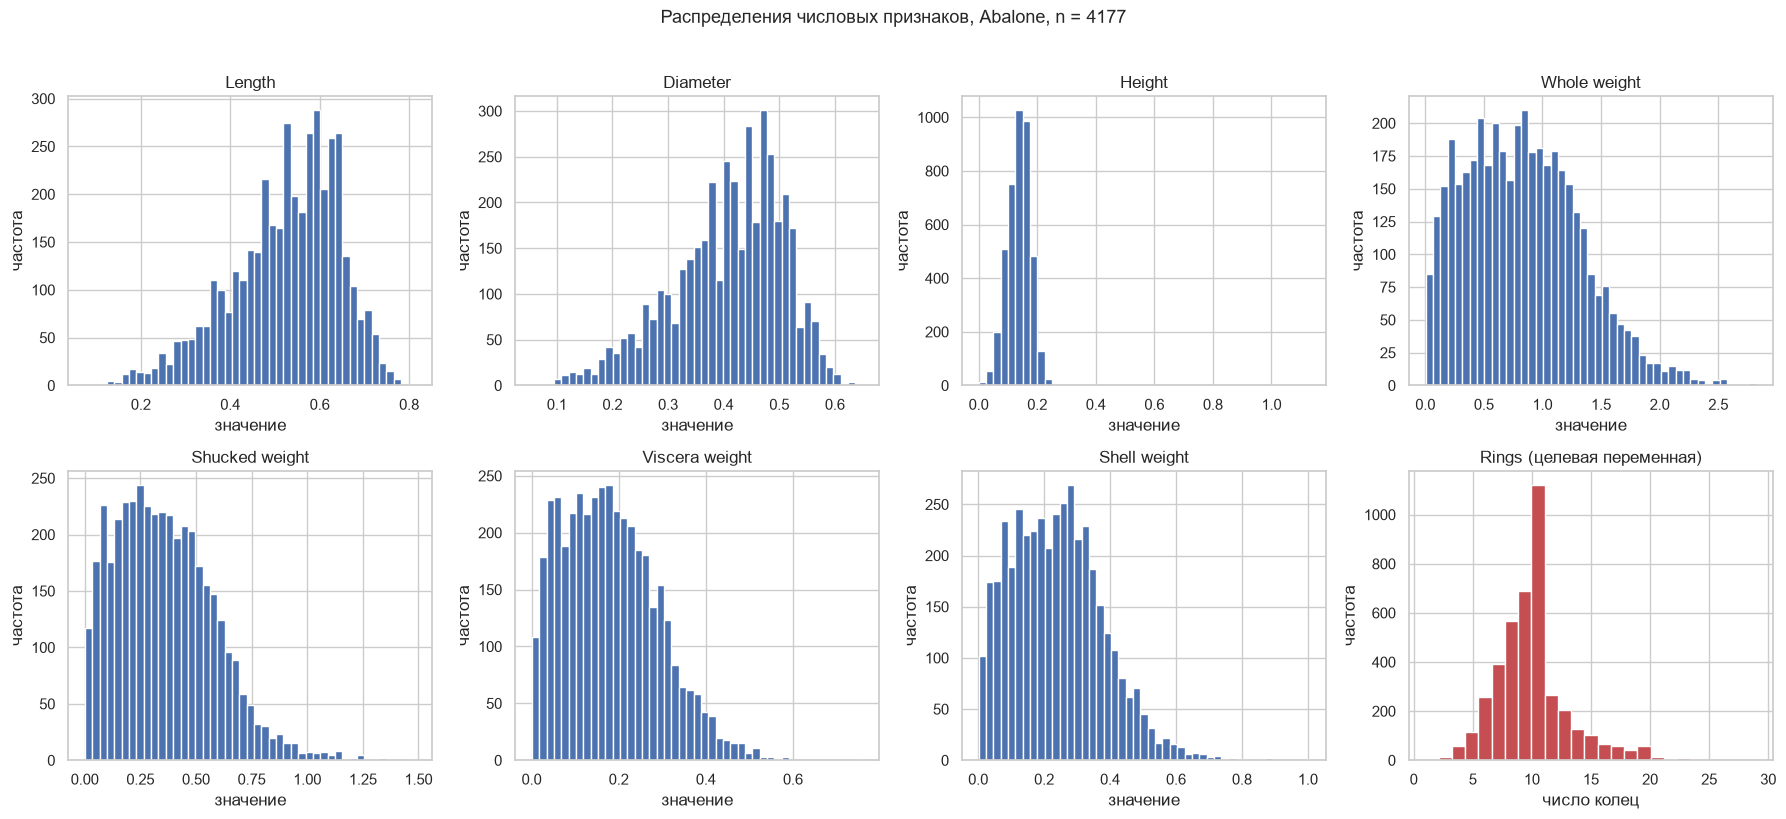

In [17]:
# Смотрим все числовые признаки на одной сетке: так сразу видно, где
# распределение «нормальное», а где это тяжёлый правый хвост.
features_to_plot = feature_columns
figure, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for axis, column in zip(axes, features_to_plot):
    axis.hist(clean[column], bins=45, color="#4c72b0", edgecolor="white")
    axis.set_title(f"{column}")
    axis.set_xlabel("значение")
    axis.set_ylabel("частота")

axes[-1].hist(clean["Rings"], bins=25, color="#c44e52", edgecolor="white")
axes[-1].set_title("Rings (целевая переменная)")
axes[-1].set_xlabel("число колец")
axes[-1].set_ylabel("частота")

figure.suptitle("Распределения числовых признаков, Abalone, n = %d" % len(clean), y=1.02)
figure.tight_layout()
plt.show()


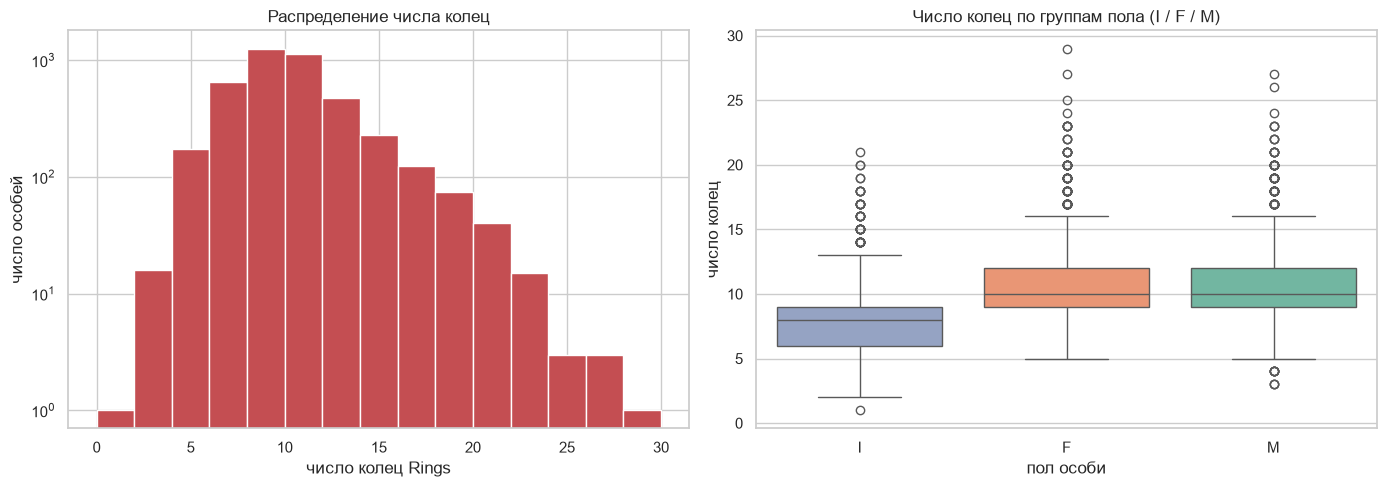

In [18]:
# Целевая переменная отдельно: её распределение определяет, какие метрики
# вообще имеют смысл. Здесь отчётливо виден тяжёлый правый хвост — редкие
# старые особи с 20-29 кольцами.
figure, (axis_hist, axis_box) = plt.subplots(1, 2, figsize=(14, 5))
axis_hist.hist(clean["Rings"], bins=range(0, 32, 2), color="#c44e52", edgecolor="white")
axis_hist.set_title("Распределение числа колец")
axis_hist.set_xlabel("число колец Rings")
axis_hist.set_ylabel("число особей")
axis_hist.set_yscale("log")

sns.boxplot(data=clean, x="Sex", y="Rings", order=["I", "F", "M"],
            hue="Sex", palette="Set2", legend=False, ax=axis_box)
axis_box.set_title("Число колец по группам пола (I / F / M)")
axis_box.set_xlabel("пол особи")
axis_box.set_ylabel("число колец")
figure.tight_layout()
plt.show()


### Признаки по группам `Sex`

Это главный визуальный аргумент в пользу того, что пол — не лишний признак,
а реальный фактор: у незрелых особей (`I`) все размеры и веса заметно меньше,
чем у самцов (`M`), а самки (`F`) занимают промежуточное положение. Если бы
ящики совпадали, кодировать пол было бы незачем.


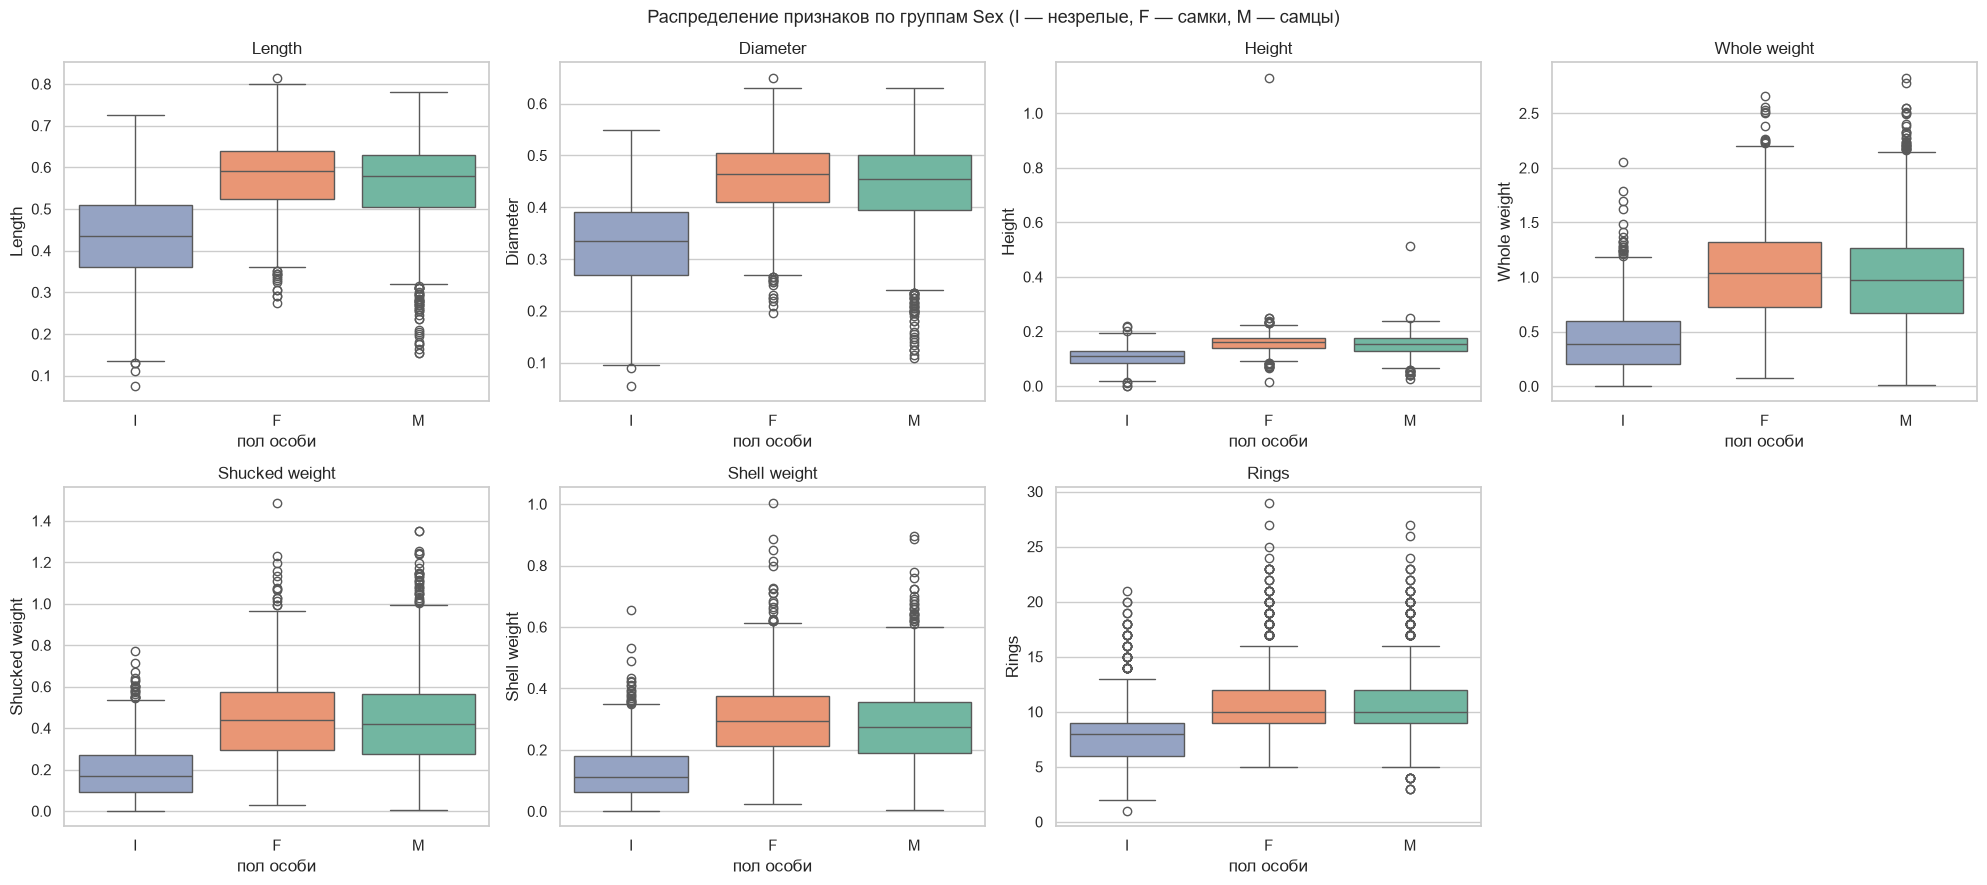

медиана признака по группам пола:
     Length  Diameter  Height  Whole weight  Shucked weight  Shell weight  Rings
Sex                                                                             
F     0.590     0.465   0.160         1.038           0.440         0.295   10.0
I     0.435     0.335   0.110         0.384           0.170         0.113    8.0
M     0.580     0.455   0.155         0.976           0.422         0.276   10.0


In [19]:
# Ящики с усами по группам пола. Разная ширина ящика = разный разброс,
# разные медианы = сдвиг. Это и есть визуальное доказательство зависимости
# признаков от пола особи.
sex_features = ["Length", "Diameter", "Height", "Whole weight",
                "Shucked weight", "Shell weight", "Rings"]
figure, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for axis, column in zip(axes, sex_features):
    sns.boxplot(data=clean, x="Sex", y=column, order=["I", "F", "M"],
                hue="Sex", palette="Set2", legend=False, ax=axis)
    axis.set_title(column)
    axis.set_xlabel("пол особи")

for axis in axes[len(sex_features):]:
    axis.set_visible(False)

figure.suptitle("Распределение признаков по группам Sex (I — незрелые, F — самки, M — самцы)")
figure.tight_layout()
plt.show()

# Числом подтверждаем то, что видно на графике: медиана каждого признака по группам.
medians_by_sex = clean.groupby("Sex")[sex_features].median().round(3)
print("медиана признака по группам пола:")
print(medians_by_sex)


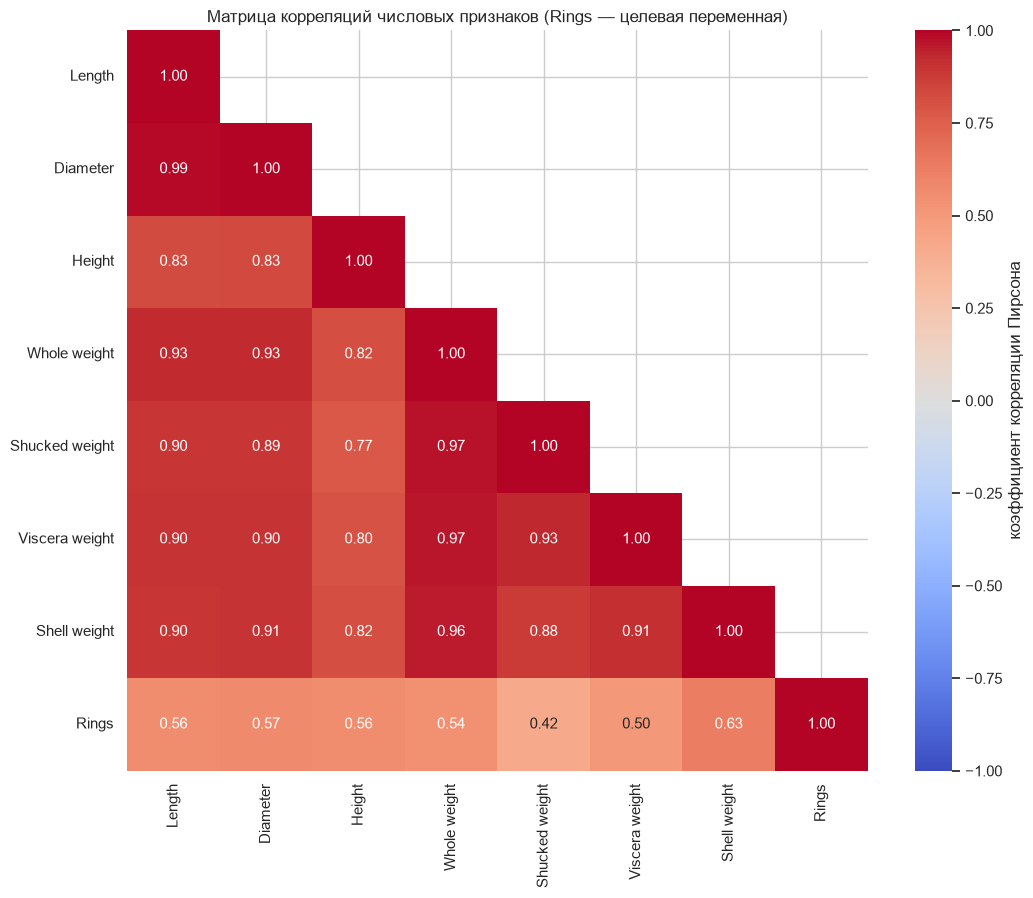

Shell weight      0.627574
Diameter          0.574660
Height            0.557467
Length            0.556720
Whole weight      0.540390
Viscera weight    0.503819
Shucked weight    0.420884
Name: Rings, dtype: float64

In [20]:
# Матрица корреляций: сразу видно, что веса почти дублируют размеры, поэтому
# в линейной модели будут мультиколлинеарные признаки.
correlation = clean[numeric_columns].corr()
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)

figure, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, annot=True, fmt=".2f", mask=mask,
            cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "коэффициент корреляции Пирсона"}, ax=axis)
axis.set_title("Матрица корреляций числовых признаков (Rings — целевая переменная)")
figure.tight_layout()
plt.show()
correlation["Rings"].drop("Rings").sort_values(ascending=False)


In [21]:
# Два вывода из корреляций, на которые будет опираться вывод о модели.
# 1) Наибольшая связь с целью — у массы раковины и диаметра, а не у длины.
# 2) Признаки почти линейно зависимы друг от друга: вес 0.97 коррелирует с
#    весом мягких тканей, размеры — между собой. Это мультиколлинеарность,
#    и для метода наименьших квадратов она означает нестабильные коэффициенты.
strong_pairs = correlation[feature_columns].abs().where(
    np.triu(np.ones(correlation[feature_columns].shape, dtype=bool), k=1)).stack()

print("связь с целевой переменной:")
print(correlation["Rings"].drop("Rings").sort_values(ascending=False).round(3))
print("\nсамые связанные пары признаков:")
print(strong_pairs.sort_values(ascending=False).head(6).round(3))


связь с целевой переменной:
Shell weight      0.628
Diameter          0.575
Height            0.557
Length            0.557
Whole weight      0.540
Viscera weight    0.504
Shucked weight    0.421
Name: Rings, dtype: float64

самые связанные пары признаков:
Length          Diameter          0.987
Whole weight    Shucked weight    0.969
                Viscera weight    0.966
                Shell weight      0.955
Shucked weight  Viscera weight    0.932
Diameter        Whole weight      0.925
dtype: float64


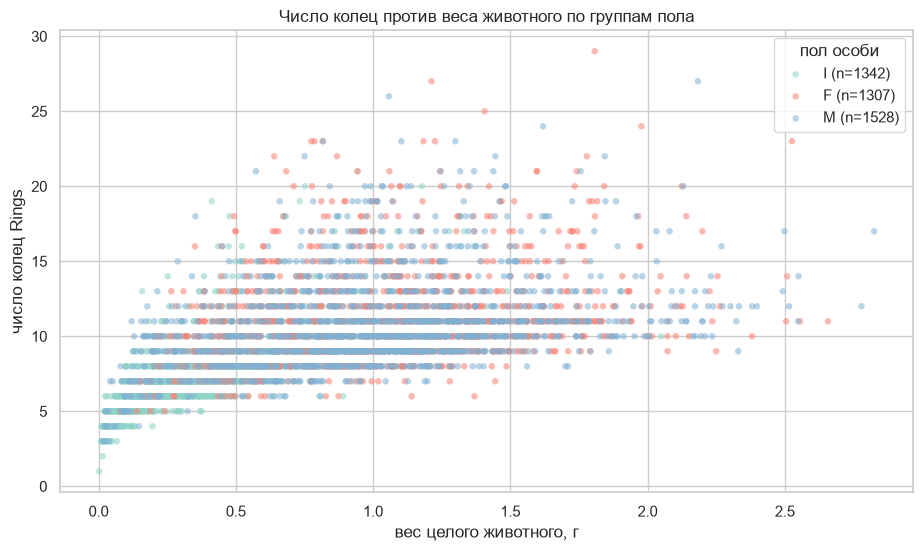

In [22]:
# Связь цели с главным признаком — и сразу видно две проблемы: зависимость
# нелинейная (рост замедляется) и разброс растёт с размером животного.
figure, axis = plt.subplots(figsize=(11, 6))
for sex, color in zip(["I", "F", "M"], ["#8dd3c7", "#fb8072", "#80b1d3"]):
    subset = clean[clean["Sex"] == sex]
    axis.scatter(subset["Whole weight"], subset["Rings"], s=22, alpha=0.55,
                 label=f"{sex} (n={len(subset)})", edgecolor="none", color=color)

axis.set_xlabel("вес целого животного, г")
axis.set_ylabel("число колец Rings")
axis.set_title("Число колец против веса животного по группам пола")
axis.legend(title="пол особи")
plt.show()


## 4. Подготовка данных

Три шага, каждый из которых меняет только обучающую выборку:

1. **Разделение** на train / validation / test с фиксированным `random_state`.
   Регрессия — не классификация, стратификация по цели здесь не нужна.
2. **One-Hot кодирование** пола. Категорий три, поэтому при кодировании одну
   категорию (`F`) делаем базовой и выбрасываем: иначе получится три
   взаимозависимых столбца, а это ломает интерпретацию коэффициентов.
3. **Масштабирование** числовых признаков. Среднее и разброс считаются
   **только на train** — если посчитать их на всей таблице, в модель бы
   попала информация о тесте, и оценка качества оказалась бы завышенной.


In [23]:
# 70 % — обучение, 30 % — поровну на валидацию и тест. Валидация нужна для
# выбора модели, тест — для финальной честной оценки; test_size указан
# долей от промежуточной выборки, поэтому в сумме получается 70/15/15.
X = clean.drop(columns="Rings")
y = clean["Rings"]

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=SEED)

print(f"обучающая:  {len(X_train)} строк · {X_train.shape[1]} признаков")
print(f"валидация:  {len(X_val)} строк")
print(f"тестовая:   {len(X_test)} строк")
print(f"среднее Rings в train / val / test: "
      f"{y_train.mean():.2f} / {y_val.mean():.2f} / {y_test.mean():.2f}")


обучающая:  2923 строк · 8 признаков
валидация:  627 строк
тестовая:   627 строк
среднее Rings в train / val / test: 9.98 / 9.74 / 9.89


In [24]:
# One-Hot кодирование: пол — категориальный признак, а модель умеет только
# числа. drop_first=True убирает первую категорию (F) — она становится
# «точкой отсчёта», а столбцы Sex_I и Sex_M показывают отклонение от неё.
def encode_sex(frame):
    """Превращает текстовый пол в два столбца-индикатора без базовой категории."""
    return pd.get_dummies(frame, columns=["Sex"], drop_first=True)

X_train = encode_sex(X_train)
X_val = encode_sex(X_val)
X_test = encode_sex(X_test)

print("набор признаков одинаков во всех выборках:",
      list(X_train.columns) == list(X_val.columns) == list(X_test.columns))
X_train.head()


набор признаков одинаков во всех выборках: True


,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Sex_I,Sex_M
2830,0.525,0.430,0.135,0.8435,0.4325,0.1800,0.1815,False,False
925,0.430,0.325,0.100,0.3645,0.1575,0.0825,0.1050,True,False
3845,0.455,0.350,0.105,0.4160,0.1625,0.0970,0.1450,False,True
547,0.205,0.155,0.045,0.0425,0.0170,0.0055,0.0155,False,True
2259,0.590,0.465,0.160,1.1005,0.5060,0.2525,0.2950,False,False


In [25]:
# Масштабирование: у весов разброс в десятки раз больше, чем у длин, и без
# приведения к общему масштабу условия нормальных уравнений плохо обусловлены.
#
# Ключевой момент честности: параметры scaler (среднее и стандартное отклонение)
# считаются ТОЛЬКО на обучающей выборке. Валидация и тест только преобразуются
# функцией transform. Если применить fit_transform ко всему датасету, модель
# получила бы сводную статистику теста — это утечка, и оценка качества была бы
# оптимистичной.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

scaling_check = pd.DataFrame({
    "среднее train (после fit)": X_train_scaled.mean(axis=0).round(6),
    "среднее val (transform)": X_val_scaled.mean(axis=0).round(3),
    "среднее test (transform)": X_test_scaled.mean(axis=0).round(3),
    "ст. отклонение train": X_train_scaled.std(axis=0).round(6),
}, index=X_train.columns)

print("средние после fit_transform(train) равны нулю, а на val и test — нет:")
print("значит, transform не подмешивал статистику других выборок")
scaling_check


средние после fit_transform(train) равны нулю, а на val и test — нет:
значит, transform не подмешивал статистику других выборок


,среднее train (после fit),среднее val (transform),среднее test (transform),ст. отклонение train
Length,0.0,-0.097,-0.023,1.0
Diameter,0.0,-0.089,-0.022,1.0
Height,0.0,-0.064,-0.032,1.0
Whole weight,0.0,-0.069,-0.033,1.0
Shucked weight,-0.0,-0.068,-0.039,1.0
Viscera weight,0.0,-0.069,-0.034,1.0
Shell weight,-0.0,-0.070,-0.046,1.0
Sex_I,-0.0,0.041,0.038,1.0
Sex_M,0.0,0.008,-0.012,1.0


## 5. Модель

Линейная регрессия ищет веса $\beta$ и свободный член $\beta_0$, которые
минимизируют сумму квадратов отклонений:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p,
\qquad
\min_{\beta}\; \sum_i (y_i - \hat{y}_i)^2
$$

Минимизация по сумме квадратов даёт closed-form решение — отсюда название
«метод наименьших квадратов» (OLS). Модель обучается одной командой `fit` и
не имеет гиперпараметров, требующих подбора, что делает её удобной отправной
точкой: всё, что она не объясняет, — это свойства данных, а не настройка
алгоритма.

Модель собирается в `Pipeline`, чтобы масштабирование гарантированно
обучалось на той выборке, на которой обучается сама регрессия. Для контрольного
эксперимента тот же конструктор умеет собирать полиномиальную и
регуляризованную версии.


In [26]:
def build_model(kind="linear", degree=2, alpha=1.0):
    """Собирает конвейер «преобразования признаков → регрессия» нужного вида.

    kind="linear" — линейная регрессия (основная модель работы);
    kind="poly"   — линейная регрессия на полиномиальных признаках (контроль нелинейности);
    kind="ridge"  — гребневая регрессия, штраф за величину коэффициентов.
    """
    if kind == "linear":
        steps = [("scaler", StandardScaler()),
                 ("regressor", LinearRegression())]
    elif kind == "poly":
        steps = [("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                 ("scaler", StandardScaler()),
                 ("regressor", LinearRegression())]
    elif kind == "ridge":
        steps = [("scaler", StandardScaler()),
                 ("regressor", Ridge(alpha=alpha, random_state=SEED))]
    else:
        raise ValueError(f"неизвестный вид модели: {kind}")
    return Pipeline(steps)

model = build_model("linear")
model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None


## 6. Обучение

Обучаем на train, смотрим качество на train и на validation. Разница между
ними сразу покажет, не переобучается ли модель: если train заметно лучше
validation, модель запомнила обучающую выборку вместо того, чтобы выучить
закономерность.


In [27]:
# Метрики всегда считаем одним и тем же способом, иначе сравнение бессмысленно.
# MAE — средняя ошибка «в кольцах», её легко объяснить преподавателю.
# RMSE — штрафует крупные промахи сильнее, потому что возводит ошибку в квадрат.
# R² — доля объяснённой дисперсии: 0 — не лучше среднего, 1 — идеально.
# MAPE — ошибка в процентах, нужна только как дополнительная точка обзора.
def regression_metrics(y_true, y_pred):
    """Возвращает MAE, RMSE, R² и MAPE одной строкой."""
    return pd.Series({
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R²": r2_score(y_true, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_true, y_pred) * 100,
    })

print("метрика посчитана для train и для validation — модель обучается на первом")


метрика посчитана для train и для validation — модель обучается на первом


Обучаем на train и сразу смотрим качество на train и на validation: разница
между ними покажет, не переобучается ли модель. Если на train заметно лучше,
значит модель запомнила обучающую выборку вместо того, чтобы выучить
закономерность.


In [28]:
# Обучаем только на train — валидация и тест в fit не участвуют.
model.fit(X_train, y_train)

print("обучение завершено")
print(f"коэффициентов: {len(model.named_steps['regressor'].coef_)} "
      f"(признаков после кодирования: {X_train.shape[1]})")
print(f"свободный член: {model.named_steps['regressor'].intercept_:.4f}")

train_scores = regression_metrics(y_train, model.predict(X_train))
val_scores = regression_metrics(y_val, model.predict(X_val))
pd.DataFrame({"обучающая": train_scores, "валидация": val_scores}).round(4)


обучение завершено
коэффициентов: 9 (признаков после кодирования: 9)
свободный член: 9.9839


,обучающая,валидация
MAE,1.5843,1.6218
RMSE,2.1957,2.2281
R²,0.5403,0.5052
"MAPE, %",15.9267,16.6299


### Честный выбор модели по валидации

Линейная регрессия — модель работы, но прежде чем заявлять результат,
проверим на валидации, не слишком ли мы её упростили. Сравниваем с двумя
кандидатами:

* **полиномиальные признаки** 2-го порядка — допускаем нелинейность;
* **гребневая регрессия (Ridge)** — штрафует большие коэффициенты, что
  должно помочь при сильной корреляции признаков между собой; силу штрафа
  $lpha$ перебираем и тоже выбираем по валидации.

Тестовая выборка в этом сравнении не участвует — именно для того, чтобы
выбор модели не подстроился под неё.


In [29]:
# Подбор кандидата целиком на валидации: тест здесь вообще не открывается.
validation_report = []
models_for_later = {"Линейная регрессия": model}

for alpha in (0.1, 1.0, 10.0, 50.0, 100.0):
    candidate = build_model("ridge", alpha=alpha)
    candidate.fit(X_train, y_train)
    models_for_later[f"Ридж, alpha={alpha:g}"] = candidate
    validation_report.append({
        "модель": f"Ридж, alpha={alpha:g}",
        "R² train": candidate.score(X_train, y_train),
        "R² validation": candidate.score(X_val, y_val),
    })

validation_report.append({
    "модель": "Линейная регрессия",
    "R² train": model.score(X_train, y_train),
    "R² validation": model.score(X_val, y_val),
})

poly_model = build_model("poly")
poly_model.fit(X_train, y_train)
models_for_later["Полином 2-го порядка"] = poly_model
validation_report.append({
    "модель": "Полином 2-го порядка",
    "R² train": poly_model.score(X_train, y_train),
    "R² validation": poly_model.score(X_val, y_val),
})

validation_table = (pd.DataFrame(validation_report)
                    .sort_values("R² validation", ascending=False)
                    .set_index("модель"))
best_on_validation = validation_table.index[0]

print("выбор сделан по валидации; тестовая выборка не участвовала")
print(f"лучшая по валидации: {best_on_validation}")

validation_table.round(4)


выбор сделан по валидации; тестовая выборка не участвовала
лучшая по валидации: Полином 2-го порядка


,R² train,R² validation
модель,,
Полином 2-го порядка,0.5993,0.5148
"Ридж, alpha=50",0.5269,0.5132
"Ридж, alpha=10",0.5375,0.5126
"Ридж, alpha=100",0.5176,0.5121
"Ридж, alpha=1",0.5402,0.5069
"Ридж, alpha=0.1",0.5403,0.5054
Линейная регрессия,0.5403,0.5052


### Коэффициенты модели

Коэффициенты читаются после стандартизации признаков, поэтому их можно
сравнивать между собой напрямую: это «вклад» признака в отклонение от
среднего в стандартных единицах.

Обратите внимание на странность: вес раковины имеет **положительный**
коэффициент, а вес мягких тканей — **отрицательный**, хотя физически оба
влияют на возраст только положительно. Это классический признак
мультиколлинеарности: признаки почти дублируют друг друга (корреляция 0.97),
и метод наименьших квадратов «перекладывает» их вклад так, чтобы сумма
осталась прежней. Отсюда практический вывод — по одному лишь коэффициенту
здесь нельзя судить о влиянии признака.


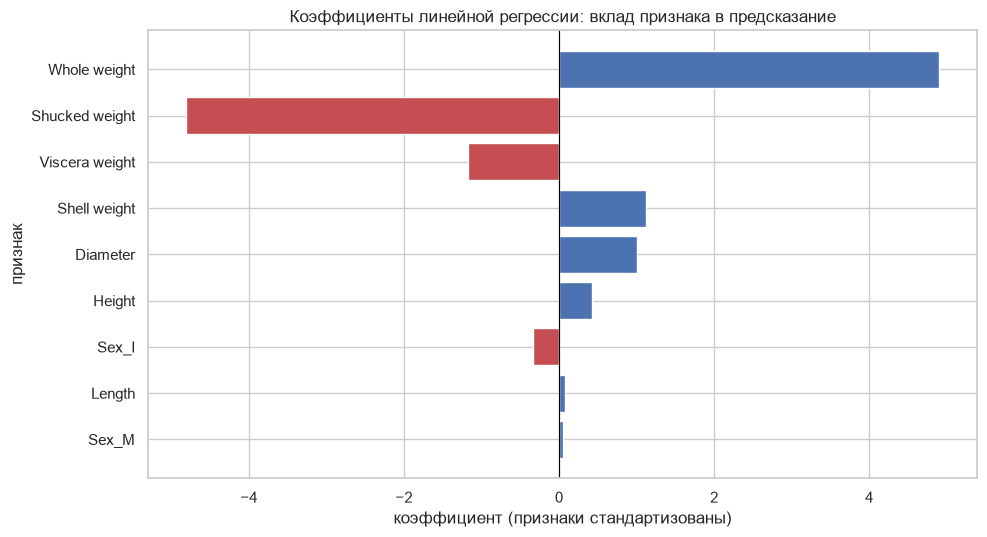

Whole weight      4.905
Shucked weight   -4.809
Viscera weight   -1.168
Shell weight      1.118
Diameter          1.012
Height            0.430
Sex_I            -0.338
Length            0.082
Sex_M             0.047
Name: коэффициент, dtype: float64

In [30]:
# Коэффициенты отсортированы по модулю — так сразу видны главные признаки.
coefficients = pd.Series(model.named_steps["regressor"].coef_,
                         index=X_train.columns,
                         name="коэффициент").sort_values(key=abs, ascending=False)

figure, axis = plt.subplots(figsize=(10, 5.5))
colors = ["#c44e52" if value < 0 else "#4c72b0" for value in coefficients]
axis.barh(coefficients.index, coefficients.values, color=colors)
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel("коэффициент (признаки стандартизованы)")
axis.set_ylabel("признак")
axis.set_title("Коэффициенты линейной регрессии: вклад признака в предсказание")
axis.invert_yaxis()
figure.tight_layout()
plt.show()

coefficients.round(3)


## 7. Оценка качества

Метрики снимаются на тестовой выборке, которая не участвовала ни в
обучении, ни в выборе модели. Одна метрика сама по себе ничего не доказывает,
поэтому рядом обязательно считается **базовая линия** — модель, которая
вообще ничего не знает о данных и всегда предсказывает одно и то же число.
Если наша модель не выигрывает у неё, работа бессмысленна.

### Почему приводим и MAE, и RMSE

* **MAE** отвечает на вопрос «на сколько колец в среднем ошибается модель» —
  это понятная человеку величина, устойчивая к выбросам.
* **RMSE** дополнительно штрафует крупные промахи. На этом датасете веса
  измеряются в граммах и у крупных ушек достигают 2.8 г, поэтому ошибка
  предсказания у крупных животных в разы больше, чем у мелких. **Из-за этого
  RMSE систематически завышает впечатление от модели:** грубая ошибка на
  одном морском еже весит столько же, сколько десятки мелких ушек.
* Вывод: **MAE — честная оценка типичной ошибки**, RMSE — показатель того,
  насколько модель опасна в худших случаях. Оба приводятся всегда, а выводы
  формулируются по обоим сразу.

Коэффициент `Sex_I` и `Sex_M` в коде — это фиктивные переменные (dummy),
о которых уже сказано в разделе подготовки.


In [31]:
# Базовая линия: модель, которая игнорирует все признаки и всегда выдаёт
# одно число. Если наша регрессия не лучше неё, она не выучила ничего.
# Обучаем на train — по правилам честной оценки базовая линия тоже не должна
# видеть тест.
dummy_mean = DummyRegressor(strategy="mean").fit(X_train, y_train)
dummy_median = DummyRegressor(strategy="median").fit(X_train, y_train)

dummy_mean_scores = regression_metrics(y_test, dummy_mean.predict(X_test))
dummy_median_scores = regression_metrics(y_test, dummy_median.predict(X_test))

print(f"предсказание базовой линии (среднее Rings в train): {y_train.mean():.4f}")
print(f"предсказание базовой линии (медиана Rings в train): {np.median(y_train):.1f}")
pd.DataFrame({"базовая: среднее": dummy_mean_scores,
              "базовая: медиана": dummy_median_scores}).round(4)


предсказание базовой линии (среднее Rings в train): 9.9839
предсказание базовой линии (медиана Rings в train): 10.0


,базовая: среднее,базовая: медиана
MAE,2.3522,2.3525
RMSE,3.2051,3.2056
R²,-0.0008,-0.0011
"MAPE, %",26.7241,26.7699


In [32]:
# Тестовая выборка открывается здесь — в первый и последний раз.
test_predictions = model.predict(X_test)
test_scores = regression_metrics(y_test, test_predictions)

print(f"тестовая выборка: {len(y_test)} строк")
print("\nМетрики линейной регрессии на тесте:")
print(test_scores.round(4))
print(f"\nсредняя ошибка — {test_scores['MAE']:.2f} кольца, "
      f"типичное отклонение — {test_scores['RMSE']:.2f} кольца")
print(f"модель объясняет {test_scores['R²']:.1%} изменчивости числа колец")


тестовая выборка: 627 строк

Метрики линейной регрессии на тесте:
MAE         1.5446
RMSE        2.1460
R²          0.5513
MAPE, %    15.7743
dtype: float64

средняя ошибка — 1.54 кольца, типичное отклонение — 2.15 кольца
модель объясняет 55.1% изменчивости числа колец


In [33]:
# Итоговая сверка: все обученные модели и базовые линии один раз проверяются
# на тесте. Выбор модели при этом уже сделан выше — по валидации, поэтому
# это финальная сверка, а не подбор по тесту.
final_rows = []
for name, estimator in [("Базовая: среднее", dummy_mean),
                        ("Базовая: медиана", dummy_median),
                        *models_for_later.items()]:
    scores = regression_metrics(y_test, estimator.predict(X_test))
    final_rows.append({"Модель": name, "MAE": scores["MAE"], "RMSE": scores["RMSE"],
                       "R²": scores["R²"], "MAPE, %": scores["MAPE, %"]})

final_table = pd.DataFrame(final_rows).set_index("Модель")
final_table["MAE лучше базовой, раз"] = (final_table.loc["Базовая: среднее", "MAE"] /
                                          final_table["MAE"]).round(2)
final_table["RMSE лучше базовой, раз"] = (final_table.loc["Базовая: среднее", "RMSE"] /
                                           final_table["RMSE"]).round(2)

print("все модели на тестовой выборке (n = %d)" % len(y_test))
final_table.sort_values("R²", ascending=False).round(4)


все модели на тестовой выборке (n = 627)


,MAE,RMSE,R²,"MAPE, %","MAE лучше базовой, раз","RMSE лучше базовой, раз"
Модель,,,,,,
Полином 2-го порядка,1.4774,2.0783,0.5792,14.9610,1.59,1.54
"Ридж, alpha=1",1.5451,2.1457,0.5515,15.7634,1.52,1.49
"Ридж, alpha=0.1",1.5447,2.1460,0.5514,15.7732,1.52,1.49
Линейная регрессия,1.5446,2.1460,0.5513,15.7743,1.52,1.49
"Ридж, alpha=10",1.5500,2.1515,0.5490,15.7274,1.52,1.49
"Ридж, alpha=50",1.5633,2.1801,0.5370,15.7607,1.50,1.47
"Ридж, alpha=100",1.5749,2.2037,0.5269,15.8568,1.49,1.45
Базовая: среднее,2.3522,3.2051,-0.0008,26.7241,1.00,1.00
Базовая: медиана,2.3525,3.2056,-0.0011,26.7699,1.00,1.00


In [34]:
# Ответ на главный вопрос работы: во сколько раз модель лучше базовой линии.
# Сравнивать надо по MAE (типичная ошибка) и по RMSE (худшие случаи) сразу:
# выигрыш по одной метрике при провале по другой — это не победа.
linear_row = final_table.loc["Линейная регрессия"]
baseline_row = final_table.loc["Базовая: среднее"]

mae_gain = baseline_row["MAE"] / linear_row["MAE"]
rmse_gain = baseline_row["RMSE"] / linear_row["RMSE"]
r2_gain = linear_row["R²"] - baseline_row["R²"]

print(f"MAE:  {baseline_row['MAE']:.3f} → {linear_row['MAE']:.3f}  "
      f"(в {mae_gain:.2f} раза меньше ошибки)")
print(f"RMSE: {baseline_row['RMSE']:.3f} → {linear_row['RMSE']:.3f}  "
      f"(в {rmse_gain:.2f} раза меньше ошибки)")
print(f"R²:   {baseline_row['R²']:.3f} → {linear_row['R²']:.3f}  "
      f"(прирост {r2_gain:.3f})")
print(f"доля объяснённой дисперсии выросла с 0 до {linear_row['R²']:.1%}")


MAE:  2.352 → 1.545  (в 1.52 раза меньше ошибки)
RMSE: 3.205 → 2.146  (в 1.49 раза меньше ошибки)
R²:   -0.001 → 0.551  (прирост 0.552)
доля объяснённой дисперсии выросла с 0 до 55.1%


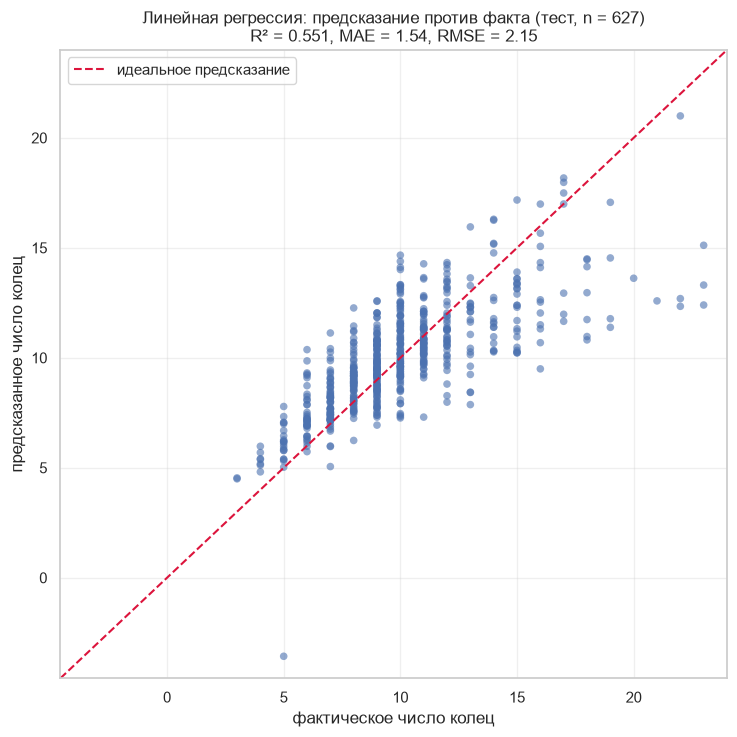

In [35]:
# Главный график регрессии: фактические значения против предсказанных.
# Точки должны лежать вдоль диагонали; если они вытянуты вдоль неё с обеих
# сторон — ошибки случайны и модель работает честно.
figure, axis = plt.subplots(figsize=(7.5, 7.5))
axis.scatter(y_test, test_predictions, s=30, alpha=0.6, color="#4c72b0", edgecolor="none")

limits = [float(min(y_test.min(), test_predictions.min())) - 1,
          float(max(y_test.max(), test_predictions.max())) + 1]
axis.plot(limits, limits, "--", color="crimson", linewidth=1.5,
          label="идеальное предсказание")
axis.set_xlim(limits)
axis.set_ylim(limits)
axis.set_xlabel("фактическое число колец")
axis.set_ylabel("предсказанное число колец")
axis.set_title(f"Линейная регрессия: предсказание против факта (тест, n = {len(y_test)})\n"
               f"R² = {test_scores['R²']:.3f}, MAE = {test_scores['MAE']:.2f}, "
               f"RMSE = {test_scores['RMSE']:.2f}")
axis.legend()
axis.grid(alpha=0.3)
figure.tight_layout()
plt.show()


### Разбор ошибок

Остаток — это разница между фактом и предсказанием, `residual = y - ŷ`.
Смотреть на них нужно обязательно: метрики дают одно число, а остатки
показывают, **где** модель ошибается.

Что ищем:

* **смещение** — если средний остаток не ноль, модель систематически
  занижает или завышает ответ;
* **система** — если остаток предсказуем по какому-то признаку, значит
  модель чего-то не учитывает;
* **форма распределения** — симметричный колокол означает, что остатки
  ведут себя как шум, и доверительные интервалы можно считать по теории;
* **зависимость от предсказания** — если разброс растёт вместе с
  предсказанием, это гетероскедастичность: одна дисперсия на все случаи
  не работает.


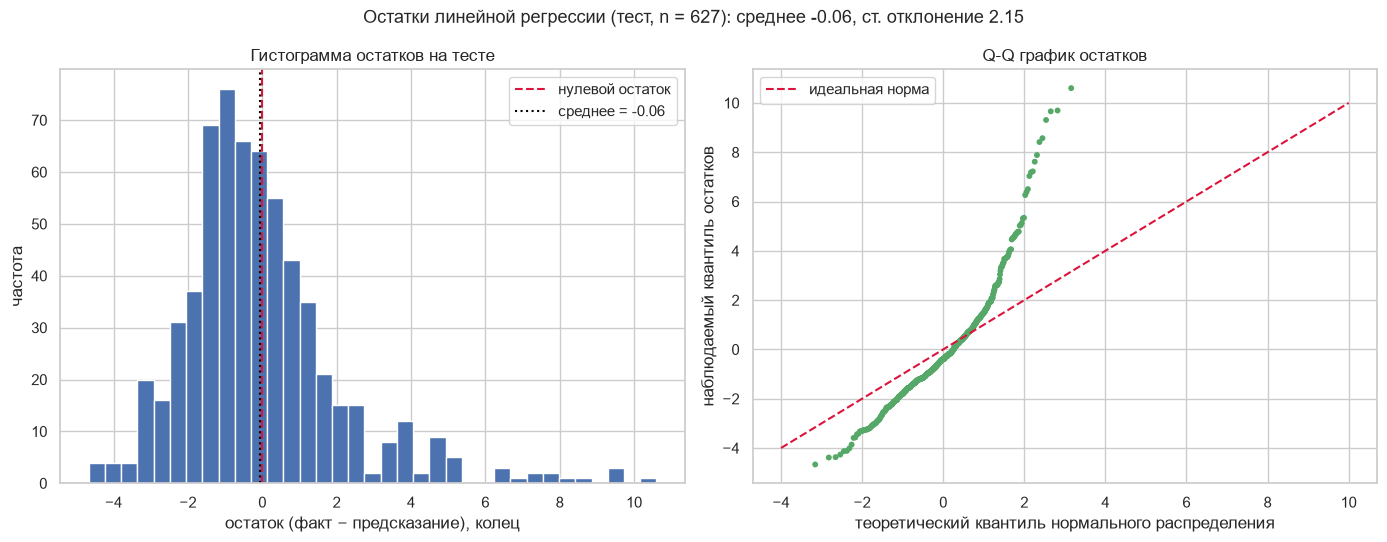

In [36]:
# Слева гистограмма остатков, справа Q-Q график: если точки Q-Q ложатся
# на прямую, остатки нормальные. Здесь они заметно отклоняются — хвост
# тяжелее нормального, о чём честно скажем в выводах.
residuals = y_test - test_predictions
theoretical_quantiles = np.array([
    NormalDist().inv_cdf((rank - 0.5) / len(residuals))
    for rank in range(1, len(residuals) + 1)
])

figure, (axis_hist, axis_qq) = plt.subplots(1, 2, figsize=(14, 5.5))
axis_hist.hist(residuals, bins=35, color="#4c72b0", edgecolor="white")
axis_hist.axvline(0, color="crimson", linestyle="--", label="нулевой остаток")
axis_hist.axvline(residuals.mean(), color="black", linestyle=":",
                  label=f"среднее = {residuals.mean():.2f}")
axis_hist.set_xlabel("остаток (факт − предсказание), колец")
axis_hist.set_ylabel("частота")
axis_hist.set_title("Гистограмма остатков на тесте")
axis_hist.legend()

axis_qq.scatter(theoretical_quantiles, np.sort(residuals), s=18,
                color="#55a868", edgecolor="none")
low, high = -4, 10
axis_qq.plot([low, high], [low, high], "--", color="crimson",
             label="идеальная норма")
axis_qq.set_xlabel("теоретический квантиль нормального распределения")
axis_qq.set_ylabel("наблюдаемый квантиль остатков")
axis_qq.set_title("Q-Q график остатков")
axis_qq.legend()

figure.suptitle(f"Остатки линейной регрессии (тест, n = {len(residuals)}): "
                f"среднее {residuals.mean():.2f}, "
                f"ст. отклонение {residuals.std():.2f}")
figure.tight_layout()
plt.show()


In [37]:
# Численное подтверждение того, что видно на графиках. Эксцесс > 0 означает
# тяжёлые хвосты: у части ушек ошибка заметно больше, чем у остальных.
residuals_series = pd.Series(residuals)
residual_stats = pd.Series({
    "среднее (смещение)": residuals_series.mean(),
    "медиана": residuals_series.median(),
    "ст. отклонение": residuals_series.std(),
    "минимум": residuals_series.min(),
    "максимум": residuals_series.max(),
    "асимметрия": residuals_series.skew(),
    "эксцесс": residuals_series.kurt(),
})
residual_stats.round(3)


среднее (смещение)    -0.055
медиана               -0.391
ст. отклонение         2.147
минимум               -4.667
максимум              10.600
асимметрия             1.473
эксцесс                3.897
dtype: float64

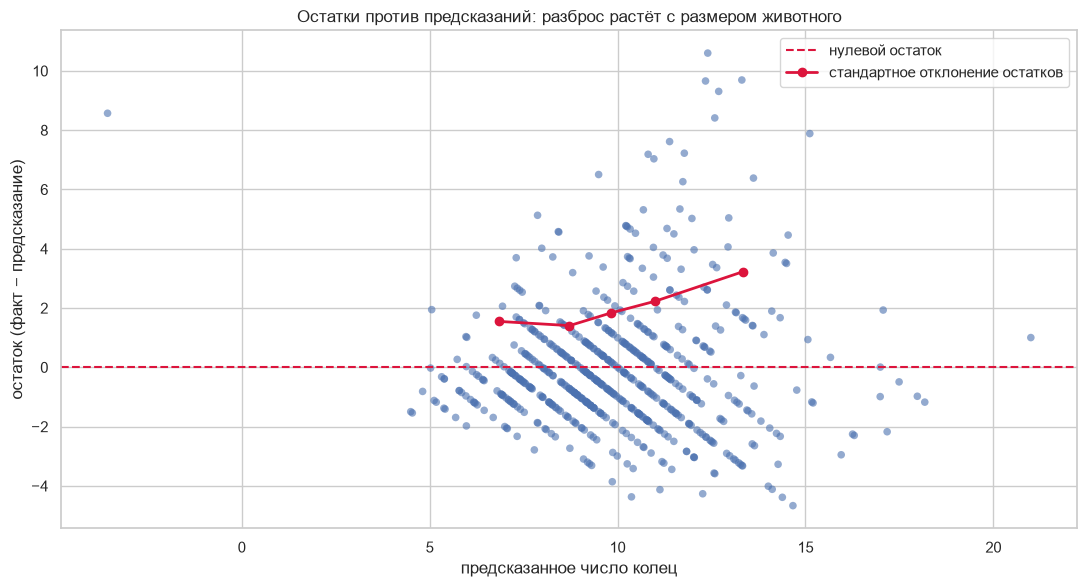

,среднее предсказание,средний остаток,ст. отклонение остатка,n
0,6.858,-0.073,1.548,126
1,8.721,-0.257,1.407,125
2,9.831,0.009,1.837,125
3,10.999,0.025,2.229,125
4,13.331,0.019,3.224,126


In [38]:
# Главный недостаток модели на этих данных — гетероскедастичность: чем крупнее
# животное, тем крупнее ошибка. Линейная модель описывает среднее, но не
# описывает разброс вокруг него.
figure, axis = plt.subplots(figsize=(11, 6))
axis.scatter(test_predictions, residuals, s=30, alpha=0.6,
             color="#4c72b0", edgecolor="none")
axis.axhline(0, color="crimson", linestyle="--", label="нулевой остаток")

# Разброс по квинтилям предсказаний показывает тренд без «помощи» scipy:
quantiles = pd.qcut(test_predictions, 5, labels=False, duplicates="drop")
spread_by_bucket = pd.Series(residuals).groupby(quantiles).std()
bucket_centers = pd.Series(test_predictions).groupby(quantiles).mean()
axis.plot(bucket_centers, spread_by_bucket, "o-", color="crimson",
          linewidth=2, label="стандартное отклонение остатков")

axis.set_xlabel("предсказанное число колец")
axis.set_ylabel("остаток (факт − предсказание)")
axis.set_title("Остатки против предсказаний: разброс растёт с размером животного")
axis.legend()
figure.tight_layout()
plt.show()

spread_table = pd.DataFrame({
    "среднее предсказание": bucket_centers,
    "средний остаток": pd.Series(residuals).groupby(quantiles).mean(),
    "ст. отклонение остатка": spread_by_bucket,
    "n": pd.Series(residuals).groupby(quantiles).size(),
}).round(3)
spread_table


In [39]:
# Численные показатели гетероскедастичности: связь ошибки с предсказанием
# и доля крупных промахов.
big_mistakes = int((residuals.abs() > 4).sum())
error_report = pd.Series({
    "связь |остаток| и предсказание": np.corrcoef(np.abs(residuals), test_predictions)[0, 1],
    "доля остатков больше 4 колец": big_mistakes / len(residuals),
    "максимальный промах, колец": float(np.abs(residuals).max()),
    "доля точных попаданий": float((residuals.abs() < 0.5).mean()),
})
error_report.round(4)


связь |остаток| и предсказание     0.2541
доля остатков больше 4 колец       0.0622
максимальный промах, колец        10.6004
доля точных попаданий              0.2297
dtype: float64

In [40]:
# Разбор конкретных ошибок: на каких ушках модель ошибается сильнее всего.
# Так ошибки перестают быть абстрактным числом.
error_details = pd.DataFrame({
    "факт": y_test,
    "предсказание": test_predictions,
    "остаток": residuals,
    "пол": clean.loc[y_test.index, "Sex"].to_numpy(),
    "вес, г": X_test["Whole weight"].to_numpy(),
    "диаметр, мм": X_test["Diameter"].to_numpy(),
})
worst_predictions = error_details.loc[
    error_details["остаток"].abs().sort_values(ascending=False).index]

print("десять худших предсказаний:")
worst_predictions.head(10).round(2)


десять худших предсказаний:


,факт,предсказание,остаток,пол,"вес, г","диаметр, мм"
678,23,12.40,10.60,F,0.82,0.38
2335,23,13.31,9.69,M,1.10,0.49
351,22,12.34,9.66,F,0.87,0.45
433,22,12.69,9.31,M,0.75,0.42
2627,5,-3.57,8.57,I,0.11,0.20
811,21,12.59,8.41,F,0.68,0.36
314,23,15.12,7.88,M,1.30,0.48
33,19,11.38,7.62,F,1.80,0.55
2202,19,11.78,7.22,M,0.92,0.40
621,18,10.81,7.19,I,0.67,0.38


## 8. Выводы

### Что получилось

* Данные проверены: **4177 строк**, пропусков **0**, полных дубликатов **0**,
  повторов по набору признаков **0**. Статистические выбросы нашлись — **153
  строки (3.7 %)** по правилу 1.5·IQR среди семи числовых признаков, — но это
  настоящие крупные и старые ушки (рекордсмен — раковина высотой 1.13 мм и
  весом 2.83 г), а не ошибки записи, поэтому они оставлены: удалять хвост
  распределения значит учить модель плохо работать там, где она нужнее всего.
* Данные разделены на **train / validation / test = 2923 / 627 / 627** при
  `random_state=42`. Параметры стандартизации считаются только на train.
* Качество на **тесте (n = 627)**: **MAE = 1.54 кольца, RMSE = 2.15 кольца,
  R² = 0.551**.
* Базовая линия `DummyRegressor(strategy="mean")` на том же тесте даёт
  **MAE = 2.35, RMSE = 3.21, R² = −0.001**. Значит, линейная регрессия ошибается
  **в 1.52 раза меньше** по MAE и **в 1.49 раза меньше** по RMSE — то есть
  она действительно выучила закономерность, а не просто повторила среднее.

### Честная часть: чего модель не умеет

**1. Остатки без системы, но не идеальные.** Средний остаток равен −0.055
кольца — смещения нет, модель не занижает и не завышает ответ систематически.
Но распределение остатков **не нормальное**: асимметрия 1.47, эксцесс 3.90,
то есть хвост заметно тяжелее нормального. Практический смысл: реальные
уверенные доверительные интервалы строить нельзя, нужен другой подход.

**2. Дисперсия растёт с размером животного — это главная проблема.**
Разбив тест по квинтилям предсказаний, видно, как растёт разброс: от 1.4 у
самых мелких предсказаний до 3.2 у самых крупных — почти в 2.3 раза.
Связь |остаток| с предсказанием — 0.25. Модель описывает среднее, но не
описывает разброс вокруг него: у крупных ушек ошибка в разы больше. Отсюда
и перекос в метриках — **RMSE (2.15) на 39 % больше MAE (1.54)**, потому что
именно крупные промахи в теории весят квадратично. По той же причине
**RMSE здесь завышает впечатление от модели**: пара морских ежей с неверным
ответом «весит» в RMSE столько же, сколько десятки мелких ушек с небольшой
ошибкой. Ориентироваться надо на MAE.

**3. Мультиколлинеарность.** Признаки почти дублируют друг друга: вес
целого животного коррелирует с весом мягких тканей на 0.97, длина — с
диаметром на 0.99. Метод наименьших квадратов при этом теряет устойчивость:
коэффициент при весе мягких тканей получился **отрицательным** (−4.81), хотя
физически такое влияние невозможно — это не «вредная призна», это следствие
того, что признаки измеряют почти одно и то же. Практический вывод: по
коэффициентам здесь судить о влиянии отдельного признака нельзя, нужна
регуляризация или переход к более устойчивым моделям.

**4. Связь нелинейная.** Проверено честно, на валидации: добавление
полиномиальных признаков 2-го порядка поднимает R² всего с 0.505 до 0.515, а
гребневая регрессия — до 0.513 при лучшем `alpha = 50`. Прирост скромный,
и это важный результат: **основной резерв лежит не в усложнении модели, а в
природе цели** (число колец растёт логарифмически с размером, а зависимость
дополнительно «прыгает» между соседними классами). Линейная регрессия
упирается в потолок, но этот потолок упирается в данные.

### Итог

Линейная регрессия на Abalone даёт **MAE ≈ 1.5 кольца при стандартном
отклонении самой цели 3.2 кольца** и объясняет 55 % изменчивости. Это
работающая отправная точка: она в 1.5 раза точнее наивного предсказания
среднего, её коэффициенты можно прочитать и обсудить, а её ошибки — честный
материал для следующего шага. Улучшать дальше имеет смысл не усложнением
линейной модели (полином и Ridge дают меньше 0.01 R²), а переходом к
нелинейным ансамблям — градиентному бустингу и случайному лесу, которые
умеют и нелинейную форму, и разный разброс для мелких и крупных животных.


In [41]:
# Короткая сводка по всем разделам — те же числа, что и выше, но в одном месте.
summary = pd.Series({
    "строк в датасете": len(clean),
    "пропусков": int(clean.isna().sum().sum()),
    "дубликатов (полных)": full_duplicates,
    "строк-выбросов": int(outlier_rows.sum()),
    "признаков после One-Hot": X_train.shape[1],
    "обучающая выборка": len(X_train),
    "валидационная выборка": len(X_val),
    "тестовая выборка": len(X_test),
    "MAE на тесте": round(test_scores["MAE"], 3),
    "RMSE на тесте": round(test_scores["RMSE"], 3),
    "R² на тесте": round(test_scores["R²"], 3),
    "MAE базовой линии": round(dummy_mean_scores["MAE"], 3),
    "RMSE базовой линии": round(dummy_mean_scores["RMSE"], 3),
    "R² базовой линии": round(dummy_mean_scores["R²"], 3),
    "во сколько раз лучше базовой (MAE)": round(mae_gain, 2),
    "во сколько раз лучше базовой (RMSE)": round(rmse_gain, 2),
    "средний остаток": round(residuals_series.mean(), 3),
    "связь |остаток| и предсказание": round(error_report.iloc[0], 3),
})
summary


строк в датасете                       4177.000
пропусков                                 0.000
дубликатов (полных)                       0.000
строк-выбросов                          153.000
признаков после One-Hot                   9.000
обучающая выборка                      2923.000
валидационная выборка                   627.000
тестовая выборка                        627.000
MAE на тесте                              1.545
RMSE на тесте                             2.146
R² на тесте                               0.551
MAE базовой линии                         2.352
RMSE базовой линии                        3.205
R² базовой линии                         -0.001
во сколько раз лучше базовой (MAE)        1.520
во сколько раз лучше базовой (RMSE)       1.490
средний остаток                          -0.055
связь |остаток| и предсказание            0.254
dtype: float64